In [2]:
import sqlite3
db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"
conn = sqlite3.connect(db_path)

# Check available tables
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table';
    """,
    conn
)

print("Available tables:")
display(tables)

Available tables:


,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean
6,crop_recommendation_fe
7,agri_yield_train_fe
8,agri_yield_test_fe
9,crop_recommendation_selected


In [3]:
sf24 = pd.read_sql_query(
    "SELECT * FROM crop_recommendation_selected",
    conn
)


Dataset shape: (2200, 13)
Number of crop categories: 22
Number of features: 12
Number of records: 2200

Training records: 1760
Testing records: 440

Training: Decision Tree

Training: Random Forest

Training: Logistic Regression

Training: KNN

Training: SVM

Training: XGBoost

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1_Score
0,XGBoost,0.9955,0.9959,0.9955,0.9954
1,Random Forest,0.9886,0.9897,0.9886,0.9887
2,Decision Tree,0.9841,0.9849,0.9841,0.9839
3,SVM,0.9795,0.9816,0.9795,0.9794
4,KNN,0.9773,0.9779,0.9773,0.9773
5,Logistic Regression,0.9727,0.9742,0.9727,0.9726


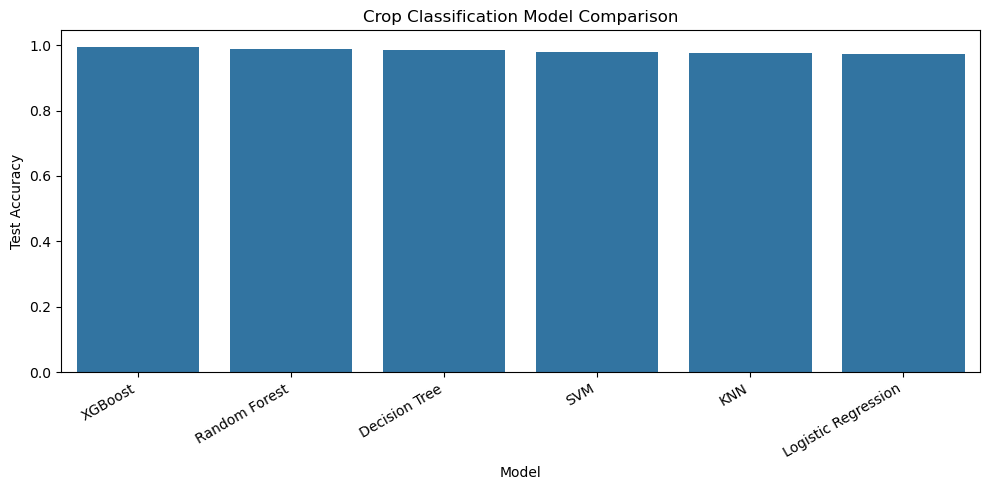


Best model by test F1-score: XGBoost
Test accuracy: 99.55 %

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       1.00      1.00      1.00        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.90      0.95        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.91      1.00      0.95        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00       

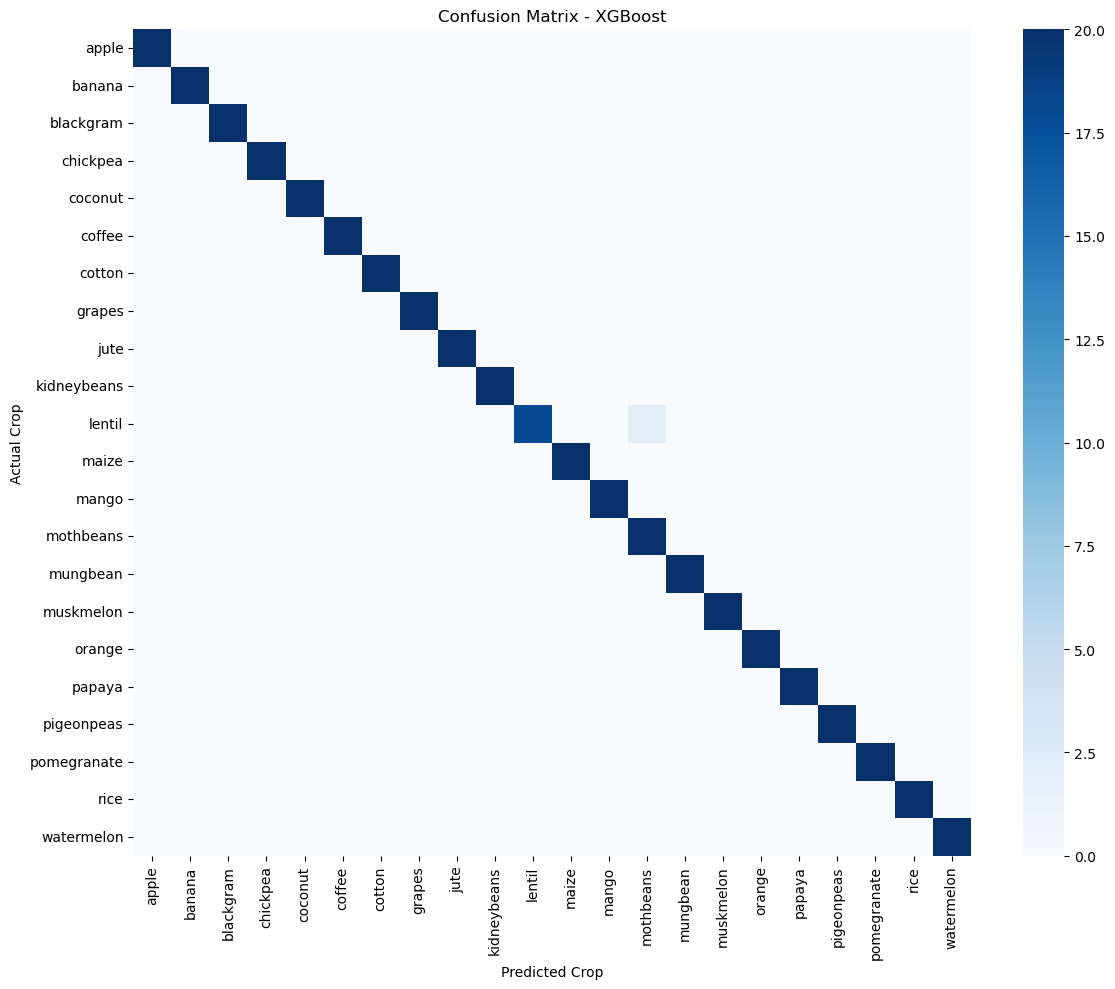


STAGE 10 COMPLETED
Best model: XGBoost
Saved files in stage10_outputs/


In [6]:

# STAGE 10: CROP RECOMMENDATION CLASSIFICATION

import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# STEP 1: LOAD AND CHECK DATA
# --------------------------------------------------

if "sf24" not in globals():
    DB_PATH = r"YOUR_ACTUAL_DATABASE_PATH.db"

    if not os.path.exists(DB_PATH):
        raise FileNotFoundError(
            "Replace DB_PATH with your actual SQLite database path."
        )

    conn = sqlite3.connect(DB_PATH)

    sf24 = pd.read_sql_query(
        "SELECT * FROM crop_recommendation_selected",
        conn
    )

    conn.close()

print("Dataset shape:", sf24.shape)
print("Number of crop categories:", sf24["label"].nunique())

# Check the dataset
if sf24["label"].isnull().any():
    raise ValueError("Missing values found in the target column.")

X = sf24.drop(columns=["label"]).copy()
y = sf24["label"].copy()

if X.isnull().sum().sum() > 0:
    raise ValueError("Missing feature values found.")

if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes):
    raise ValueError("Non-numeric feature columns found.")

if y.value_counts().min() < 2:
    raise ValueError(
        "At least one crop has fewer than two records; "
        "stratified splitting may not work."
    )

print("Number of features:", X.shape[1])
print("Number of records:", X.shape[0])

# --------------------------------------------------
# STEP 2: SPLIT DATA
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# --------------------------------------------------
# STEP 3: CREATE FIVE MODELS
# --------------------------------------------------

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    )
}

# --------------------------------------------------
# STEP 4: TRAIN AND COMPARE MODELS
# --------------------------------------------------

results = []
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions,
            average="weighted", zero_division=0
        )
    })

# --------------------------------------------------
# STEP 5: TRAIN XGBOOST WITH ENCODED LABELS
# --------------------------------------------------

try:
    from xgboost import XGBClassifier

    print("\nTraining: XGBoost")

    # Convert crop names into numeric labels
    label_encoder = LabelEncoder()
    y_train_encoded = label_encoder.fit_transform(y_train)

    xgb_model = XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric="mlogloss",
        n_jobs=-1
    )

    xgb_model.fit(X_train, y_train_encoded)

    # Predict numeric labels and convert them back to crop names
    xgb_predictions_encoded = xgb_model.predict(X_test).astype(int)

    xgb_predictions = label_encoder.inverse_transform(
        xgb_predictions_encoded
    )

    trained_models["XGBoost"] = xgb_model

    results.append({
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, xgb_predictions),
        "Precision": precision_score(
            y_test, xgb_predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, xgb_predictions,
            average="weighted", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, xgb_predictions,
            average="weighted", zero_division=0
        )
    })

except ImportError:
    print("XGBoost is not installed. Five models will be compared.")

# --------------------------------------------------
# STEP 6: DISPLAY MODEL COMPARISON
# --------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1_Score",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
display(results_df.round(4))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Crop Classification Model Comparison")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# STEP 7: EVALUATE THE BEST MODEL
# --------------------------------------------------

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

if best_model_name == "XGBoost":
    best_predictions = label_encoder.inverse_transform(
        best_model.predict(X_test).astype(int)
    )
else:
    best_predictions = best_model.predict(X_test)

print("\nBest model by test F1-score:", best_model_name)

print(
    "Test accuracy:",
    round(accuracy_score(y_test, best_predictions) * 100, 2),
    "%"
)

print("\nClassification Report:")

print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=sorted(y.unique())
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# STEP 8: SAVE RESULTS AND MODEL
# --------------------------------------------------

os.makedirs("stage10_outputs", exist_ok=True)

# Save comparison table
results_df.to_csv(
    "stage10_outputs/model_comparison.csv",
    index=False
)

# Save actual and predicted labels
prediction_results = pd.DataFrame({
    "Actual_Crop": y_test.reset_index(drop=True),
    "Predicted_Crop": pd.Series(best_predictions)
})

prediction_results.to_csv(
    "stage10_outputs/best_model_predictions.csv",
    index=False
)

# Save classification report
report = classification_report(
    y_test,
    best_predictions,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "stage10_outputs/classification_report.csv"
)

# Save the selected model and its feature names
model_package = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_names": X.columns.tolist()
}

# Include the encoder when saving XGBoost
if best_model_name == "XGBoost":
    model_package["label_encoder"] = label_encoder

joblib.dump(
    model_package,
    "stage10_outputs/best_crop_model.pkl"
)

print("\nSTAGE 10 COMPLETED")
print("Best model:", best_model_name)
print("Saved files in stage10_outputs/")

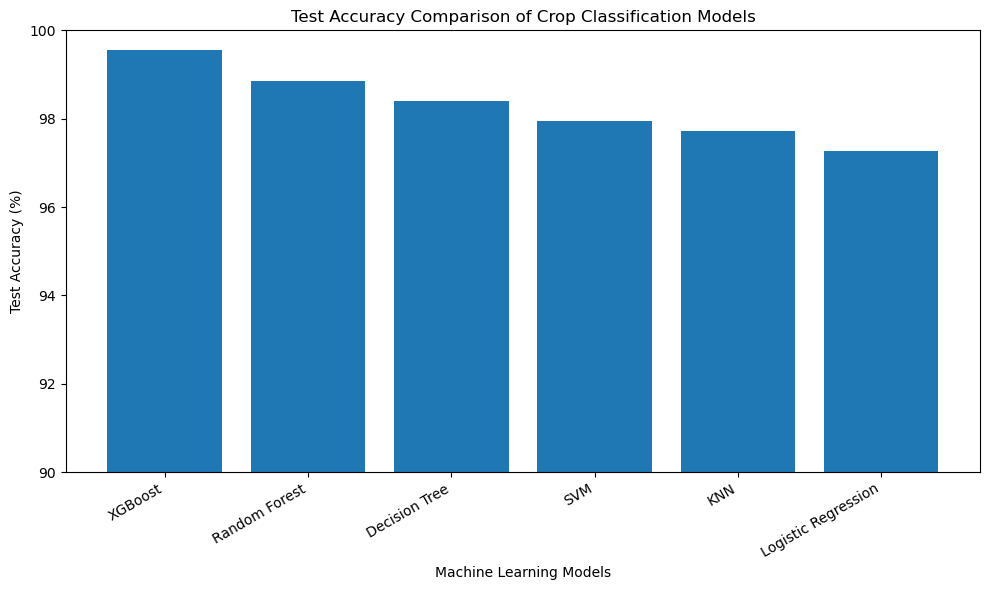

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Model names and their test accuracy
models = [
    "XGBoost",
    "Random Forest",
    "Decision Tree",
    "SVM",
    "KNN",
    "Logistic Regression"
]

accuracy = [
    0.99545,
    0.98864,
    0.98409,
    0.97955,
    0.97727,
    0.97273
]

# Create a DataFrame
comparison = pd.DataFrame({
    "Model": models,
    "Test Accuracy": accuracy
})

# Convert accuracy into percentage
comparison["Test Accuracy"] = comparison["Test Accuracy"] * 100

# Sort models by accuracy
comparison = comparison.sort_values(
    by="Test Accuracy",
    ascending=False
)

# Plot the graph
plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["Test Accuracy"]
)

plt.title("Test Accuracy Comparison of Crop Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(90, 100)
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()